In [45]:
#!pip install pandas openpyxl matplotlib sentence-transformers vendi-score sklearn scikit-learn krippendorff matplotlib -q tf-keras

In [46]:
# Install as scikit-learn (import name is sklearn — do NOT pip install sklearn)
#!pip install scikit-learn krippendorff matplotlib -q

In [47]:
#!pip install sentence-transformers

In [48]:
import krippendorff
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from itertools import combinations
from sklearn.metrics import cohen_kappa_score
from pathlib import Path
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import combinations
import krippendorff
from sklearn.metrics import cohen_kappa_score


## Inter-Rater Reliability (IRR)

Analysis of `Veteran_Tweet_Label_PTSD.csv` — eight reviewers each labeled 149 tweets using a 7-category scheme (6 defined levels + "Other"). Metrics:

- **Percent agreement** — share of raters picking the same label on each tweet
- **Fleiss' κ** — chance-corrected agreement for 3+ raters (nominal)
- **Krippendorff's α** — generalization that handles multiple raters; reported for nominal and ordinal scales
- **Pairwise Cohen's κ** — agreement between each reviewer pair

Interpretation (Landis & Koch): κ < 0.20 = slight, 0.21–0.40 = fair, 0.41–0.60 = moderate, 0.61–0.80 = substantial, > 0.80 = almost perfect.

In [49]:
PTSD_DATA_PATH = Path("Veteran_Tweet_Label_PTSD.csv")
veteran_tweet_labels = pd.read_csv(PTSD_DATA_PATH)

REVIEWER_COLS = [c for c in veteran_tweet_labels.columns if c != "tweet"]
ratings = veteran_tweet_labels[REVIEWER_COLS].copy()

LABELS = sorted(ratings.stack().unique())
ORDINAL_MAP = {
    "1-No Concern": 1,
    "2- Distressed Self-Disclosure": 2,
    "3-Self-Identified Crisis Symptoms and Seeking Support": 3,
    "4- Self-Identified Crisis Symptoms but Not Seeking Support": 4,
    "5- Acute Crisis with Suicidal Ideation": 5
}

print(f"{len(REVIEWER_COLS)} reviewers × {len(ratings)} tweets")
print("Labels:", LABELS)

8 reviewers × 149 tweets
Labels: ['1-No Concern', '2- Distressed Self-Disclosure', '3-Self-Identified Crisis Symptoms and Seeking Support', '4- Self-Identified Crisis Symptoms but Not Seeking Support', '5- Acute Crisis with Suicidal Ideation', '6- Not Relevant to the Research', 'Other']


In [50]:
def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    """Fleiss' kappa for a subjects × raters nominal matrix."""
    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {label: i for i, label in enumerate(labels)}

    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]
    counts = np.zeros((n_subjects, len(labels)))

    for i, row in enumerate(rating_matrix.values):
        for label in row:
            counts[i, label_to_idx[label]] += 1

    n = n_raters
    p_i = (counts * (counts - 1)).sum(axis=1) / (n * (n - 1))
    p_bar = p_i.mean()
    p_j = counts.sum(axis=0) / (n_subjects * n)
    p_e = (p_j**2).sum()
    return (p_bar - p_e) / (1 - p_e)


def percent_agreement(row: pd.Series) -> float:
    counts = Counter(row.values)
    return counts.most_common(1)[0][1] / len(row)


def krippendorff_alpha(rating_matrix: pd.DataFrame, level: str) -> float:
    if level == "nominal":
        encoded = rating_matrix.T.replace(
            {label: i for i, label in enumerate(LABELS)}
        ).to_numpy(dtype=float)
    else:
        encoded = rating_matrix.apply(lambda col: col.map(ORDINAL_MAP)).T.to_numpy(dtype=float)

    return krippendorff.alpha(reliability_data=encoded, level_of_measurement=level)


tweet_agreement = ratings.apply(percent_agreement, axis=1)

irr_summary = pd.Series(
    {
        "Mean percent agreement": tweet_agreement.mean(),
        "Tweets with full agreement (8/8)": (tweet_agreement == 1.0).sum(),
        "Tweets with majority agreement (≥5/8)": (tweet_agreement >= 5 / 8).sum(),
        "Fleiss' kappa (nominal)": fleiss_kappa(ratings),
        "Krippendorff's alpha (nominal)": krippendorff_alpha(ratings, "nominal"),
        "Krippendorff's alpha (ordinal, excl. Other)": krippendorff_alpha(ratings, "ordinal"),
    }
)

irr_summary.to_frame("Value").round(4)

C:\Users\nipua\AppData\Local\Temp\ipykernel_4024\3940280375.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  encoded = rating_matrix.T.replace(


,Value
Mean percent agreement,0.5998
Tweets with full agreement (8/8),0.0000
Tweets with majority agreement (≥5/8),88.0000
Fleiss' kappa (nominal),0.1430
Krippendorff's alpha (nominal),0.1437
"Krippendorff's alpha (ordinal, excl. Other)",0.4941


Nominal Cohen's κ — mean: 0.156, min: -0.012, max: 0.390
Ordinal Cohen's κ (quadratic weighted) — mean: 0.449, min: 0.216, max: 0.735


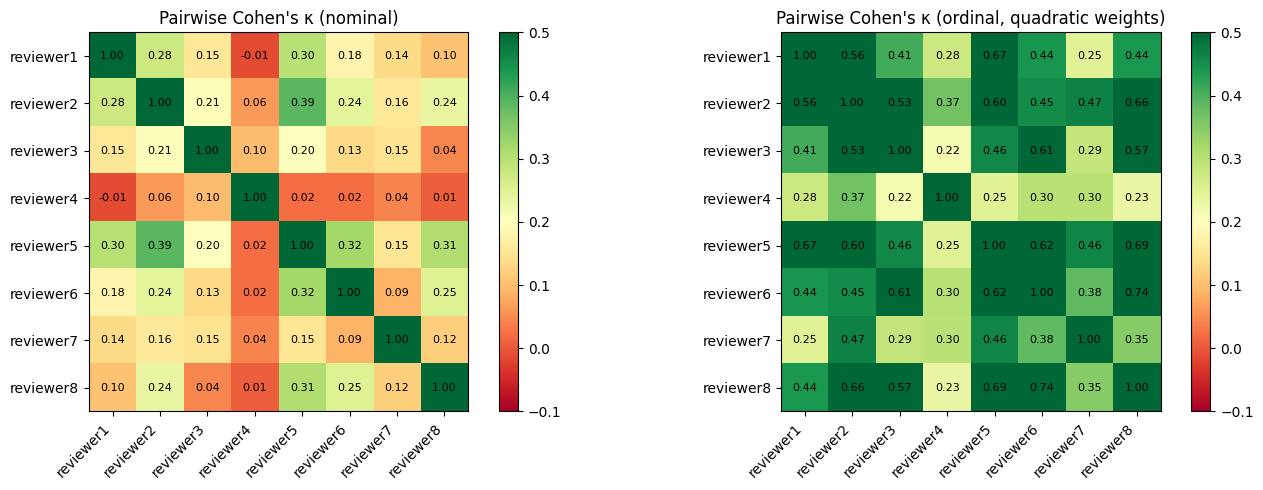

In [51]:
# Pairwise Cohen's kappa (nominal and ordinal-weighted)
pairwise_nominal = pd.DataFrame(index=REVIEWER_COLS, columns=REVIEWER_COLS, dtype=float)
pairwise_weighted = pd.DataFrame(index=REVIEWER_COLS, columns=REVIEWER_COLS, dtype=float)

ordinal_ratings = ratings.apply(lambda col: col.map(ORDINAL_MAP))
ORDINAL_LABELS = sorted(ORDINAL_MAP.values())

for a, b in combinations(REVIEWER_COLS, 2):
    pairwise_nominal.loc[a, b] = cohen_kappa_score(ratings[a], ratings[b])
    pairwise_nominal.loc[b, a] = pairwise_nominal.loc[a, b]

    mask = ordinal_ratings[a].notna() & ordinal_ratings[b].notna()
    pairwise_weighted.loc[a, b] = cohen_kappa_score(
        ordinal_ratings.loc[mask, a].astype(int),
        ordinal_ratings.loc[mask, b].astype(int),
        labels=ORDINAL_LABELS,
        weights="quadratic",
    )
    pairwise_weighted.loc[b, a] = pairwise_weighted.loc[a, b]

for col in REVIEWER_COLS:
    pairwise_nominal.loc[col, col] = 1.0
    pairwise_weighted.loc[col, col] = 1.0

pairwise_nominal.index = REVIEWER_COLS
pairwise_nominal.columns = REVIEWER_COLS
pairwise_weighted.index = REVIEWER_COLS
pairwise_weighted.columns = REVIEWER_COLS

print(
    f"Nominal Cohen's κ — "
    f"mean: {pairwise_nominal.where(~np.eye(len(REVIEWER_COLS), dtype=bool)).stack().mean():.3f}, "
    f"min: {pairwise_nominal.where(~np.eye(len(REVIEWER_COLS), dtype=bool)).stack().min():.3f}, "
    f"max: {pairwise_nominal.where(~np.eye(len(REVIEWER_COLS), dtype=bool)).stack().max():.3f}"
)

print(
    f"Ordinal Cohen's κ (quadratic weighted) — "
    f"mean: {pairwise_weighted.where(~np.eye(len(REVIEWER_COLS), dtype=bool)).stack().mean():.3f}, "
    f"min: {pairwise_weighted.where(~np.eye(len(REVIEWER_COLS), dtype=bool)).stack().min():.3f}, "
    f"max: {pairwise_weighted.where(~np.eye(len(REVIEWER_COLS), dtype=bool)).stack().max():.3f}"
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, matrix, title in zip(
    axes,
    [pairwise_nominal, pairwise_weighted],
    ["Pairwise Cohen's κ (nominal)", "Pairwise Cohen's κ (ordinal, quadratic weights)"],
):
    im = ax.imshow(matrix.astype(float), vmin=-0.1, vmax=0.5, cmap="RdYlGn")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)

    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            val = matrix.iloc[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

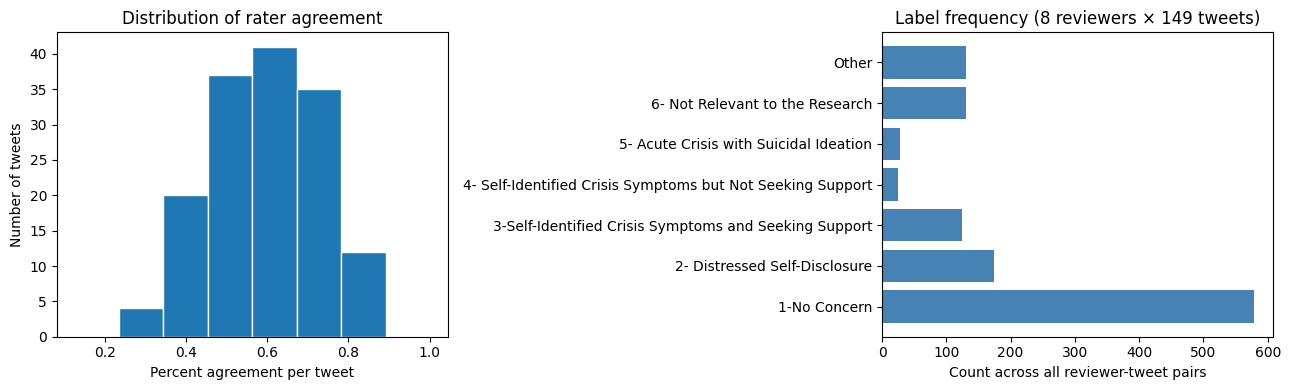

,tweet,agreement,reviewer1,reviewer2,reviewer3,reviewer4,reviewer5,reviewer6,reviewer7,reviewer8
7,I’m done #bipolar #bipolarclub113.1,0.250,Other,2- Distressed Self-Disclosure,2- Distressed Self-Disclosure,1-No Concern,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation,4- Self-Identified Crisis Symptoms but Not See...,3-Self-Identified Crisis Symptoms and Seeking ...
5,I’m done #bipolar #bipolarclub113,0.250,Other,2- Distressed Self-Disclosure,2- Distressed Self-Disclosure,6- Not Relevant to the Research,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation,4- Self-Identified Crisis Symptoms but Not See...,3-Self-Identified Crisis Symptoms and Seeking ...
28,Fuckin ideation won’t go away HELP @BipolarClu...,0.250,3-Self-Identified Crisis Symptoms and Seeking ...,3-Self-Identified Crisis Symptoms and Seeking ...,5- Acute Crisis with Suicidal Ideation,1-No Concern,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,1-No Concern,5- Acute Crisis with Suicidal Ideation
21,My current mood is.....probably not safe enoug...,0.250,Other,3-Self-Identified Crisis Symptoms and Seeking ...,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,2- Distressed Self-Disclosure,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation,3-Self-Identified Crisis Symptoms and Seeking ...
9,Dark too dark falling falling fading.....gone,0.375,Other,Other,2- Distressed Self-Disclosure,1-No Concern,5- Acute Crisis with Suicidal Ideation,3-Self-Identified Crisis Symptoms and Seeking ...,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation
10,"Found this from a “friend “ I know on fb,shit ...",0.375,1-No Concern,2- Distressed Self-Disclosure,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,1-No Concern,6- Not Relevant to the Research
3,Round&round electricity goes where it stop PLE...,0.375,2- Distressed Self-Disclosure,1-No Concern,1-No Concern,4- Self-Identified Crisis Symptoms but Not See...,2- Distressed Self-Disclosure,1-No Concern,2- Distressed Self-Disclosure,6- Not Relevant to the Research
4,Dear winter weather GET THE FUCK OUT OF TEXAS ...,0.375,1-No Concern,2- Distressed Self-Disclosure,6- Not Relevant to the Research,1-No Concern,6- Not Relevant to the Research,2- Distressed Self-Disclosure,3-Self-Identified Crisis Symptoms and Seeking ...,2- Distressed Self-Disclosure
19,I’m only saying this once FUCK MARILYN MANSON!11,0.375,2- Distressed Self-Disclosure,1-No Concern,1-No Concern,1-No Concern,6- Not Relevant to the Research,6- Not Relevant to the Research,2- Distressed Self-Disclosure,6- Not Relevant to the Research
18,Hi everyone #PTSDChat113,0.375,1-No Concern,1-No Concern,3-Self-Identified Crisis Symptoms and Seeking ...,4- Self-Identified Crisis Symptoms but Not See...,1-No Concern,3-Self-Identified Crisis Symptoms and Seeking ...,2- Distressed Self-Disclosure,3-Self-Identified Crisis Symptoms and Seeking ...


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(tweet_agreement, bins=8, range=(0.125, 1.001), edgecolor="white")
axes[0].set_xlabel("Percent agreement per tweet")
axes[0].set_ylabel("Number of tweets")
axes[0].set_title("Distribution of rater agreement")

label_counts = ratings.stack().value_counts().sort_index()
axes[1].barh(label_counts.index, label_counts.values, color="steelblue")
axes[1].set_xlabel("Count across all reviewer-tweet pairs")
axes[1].set_title("Label frequency (8 reviewers × 149 tweets)")

plt.tight_layout()
plt.show()

# Tweets with the lowest agreement
low_agreement = (
    veteran_tweet_labels.assign(agreement=tweet_agreement)
    .sort_values("agreement")
    .loc[:, ["tweet", "agreement", *REVIEWER_COLS]]
    .head(10)
)
low_agreement

### IRR summary

Overall agreement is **low to fair** across metrics (κ/α ≈ 0.14–0.21). No tweet received unanimous labels from all 8 reviewers. The mean percent agreement is ~60%, meaning raters typically split 5–3 or 4–4 on a given tweet.

Possible contributors:
- **Ambiguous boundary cases** between adjacent severity levels (especially 2 vs 3 vs 4)
- **"Other" and "6- Not Relevant"** used inconsistently for off-topic or hard-to-classify tweets
- **Subjective interpretation** of whether a tweet shows crisis symptoms vs distress vs neutral content

Next steps could include: consensus meetings on high-disagreement tweets, collapsing adjacent categories, or computing IRR after excluding "Other"/"Not Relevant" tweets.

In [54]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

In [55]:
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from vendi_score import vendi

# Read data
df = pd.read_csv("Veteran_Tweet_Label_PTSD.csv")

# Replace 'tweet' with the actual tweet column name if different
tweets = df["tweet"].astype(str).tolist()

# Load embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Compute embeddings
embeddings = model.encode(tweets, normalize_embeddings=True)

# Similarity matrix
S = cosine_similarity(embeddings)

# Overall Tweet Vendi Score
tweet_vendi = vendi.score_K(S)

# Normalize by the number of tweets
n_tweets = len(tweets)
tweet_vendi_normalized = tweet_vendi / n_tweets

print(f"Number of Tweets: {n_tweets}")
print(f"Overall Tweet Vendi Score: {tweet_vendi:.4f}")
print(f"Normalized Tweet Vendi Score: {tweet_vendi_normalized:.4f} ({tweet_vendi_normalized*100:.2f}%)")

ValueError: Your currently installed version of Keras is Keras 3, but this is not yet supported in Transformers. Please install the backwards-compatible tf-keras package with `pip install tf-keras`.

In [ ]:
import pandas as pd
import numpy as np
from vendi_score import vendi

# Read data
df = pd.read_csv("Veteran_Tweet_Label_PTSD.csv")

# Keep only reviewer columns
reviewer_cols = [c for c in df.columns if c.startswith("reviewer")]
annotations_df = df[reviewer_cols]

############################################################
# Reviewer Vendi Score
############################################################

n_reviewers = annotations_df.shape[1]

S_reviewers = np.zeros((n_reviewers, n_reviewers))

for i in range(n_reviewers):
    for j in range(n_reviewers):
        a = annotations_df.iloc[:, i]
        b = annotations_df.iloc[:, j]

        valid = a.notna() & b.notna()

        if valid.sum() == 0:
            sim = 0
        else:
            sim = np.mean(a[valid] == b[valid])

        S_reviewers[i, j] = sim

# Compute Reviewer Vendi Score
reviewer_vendi = vendi.score_K(S_reviewers)

# Normalize by the number of reviewers
reviewer_vendi_normalized = reviewer_vendi / n_reviewers

print(f"Number of Reviewers: {n_reviewers}")
print(f"Reviewer Vendi Score: {reviewer_vendi:.4f}")
print(f"Normalized Reviewer Vendi Score: {reviewer_vendi_normalized:.4f} ({reviewer_vendi_normalized*100:.2f}%)")

Number of Reviewers: 8
Reviewer Vendi Score: 5.3579
Normalized Reviewer Vendi Score: 0.6697 (66.97%)


### Merge: Other + Not Relevant to the Research

In [ ]:
import pandas as pd
import numpy as np
from vendi_score import vendi

# ============================================================
# Read merged data
# ============================================================

df = pd.read_csv("Veteran_Tweet_Label_PTSD_Other_Not_Relevant_merged.csv")

# ============================================================
# Keep reviewer columns
# ============================================================

reviewer_cols = [
    c for c in df.columns
    if c.startswith("reviewer")
]

ratings = df[reviewer_cols].copy()

# ============================================================
# Check final labels
# ============================================================

print("Labels in merged dataset:")
print(
    ratings.stack()
    .value_counts()
)

# ============================================================
# Reviewer Vendi Score
# ============================================================

n_reviewers = ratings.shape[1]

S_reviewers = np.zeros(
    (n_reviewers, n_reviewers)
)

for i in range(n_reviewers):

    for j in range(n_reviewers):

        a = ratings.iloc[:, i]
        b = ratings.iloc[:, j]

        # Compare only where both reviewers have a label
        valid = (
            a.notna()
            & b.notna()
        )

        if valid.sum() == 0:
            sim = 0
        else:
            sim = np.mean(
                a[valid] == b[valid]
            )

        S_reviewers[i, j] = sim

# ============================================================
# Compute Reviewer Vendi Score
# ============================================================

reviewer_vendi = vendi.score_K(
    S_reviewers
)

# ============================================================
# Normalize
# ============================================================

reviewer_vendi_normalized = (
    reviewer_vendi / n_reviewers
)

# ============================================================
# Results
# ============================================================

print("\n==========================================")
print("REVIEWER VENDI SCORE")
print("==========================================")

print(f"Number of Tweets: {len(df)}")
print(f"Number of Reviewers: {n_reviewers}")

print(
    f"Reviewer Vendi Score: "
    f"{reviewer_vendi:.4f}"
)

print(
    f"Normalized Reviewer Vendi Score: "
    f"{reviewer_vendi_normalized:.4f} "
    f"({reviewer_vendi_normalized * 100:.2f}%)"
)

Labels in merged dataset:
1-No Concern                                                  579
Other                                                         261
2- Distressed Self-Disclosure                                 174
3-Self-Identified Crisis Symptoms and Seeking Support         125
5- Acute Crisis with Suicidal Ideation                         28
4- Self-Identified Crisis Symptoms but Not Seeking Support     25
Name: count, dtype: int64

REVIEWER VENDI SCORE
Number of Tweets: 149
Number of Reviewers: 8
Reviewer Vendi Score: 5.1957
Normalized Reviewer Vendi Score: 0.6495 (64.95%)


Labels in merged dataset:
1-No Concern                                                  579
Other                                                         261
2- Distressed Self-Disclosure                                 174
3-Self-Identified Crisis Symptoms and Seeking Support         125
5- Acute Crisis with Suicidal Ideation                         28
4- Self-Identified Crisis Symptoms but Not Seeking Support     25
Name: count, dtype: int64

INTER-RATER RELIABILITY
                                          Value
Number of tweets                       149.0000
Number of reviewers                      8.0000
Mean percent agreement                   0.6040
Tweets with full agreement (8/8)         0.0000
Tweets with majority agreement (≥5/8)   92.0000
Fleiss' kappa (nominal)                  0.1442
Krippendorff's alpha (nominal)           0.1449
Krippendorff's alpha (ordinal)           0.4941

PAIRWISE COHEN'S KAPPA
Nominal Cohen's κ — mean: 0.155, min: -0.017, max: 0.430
Weighted Cohen

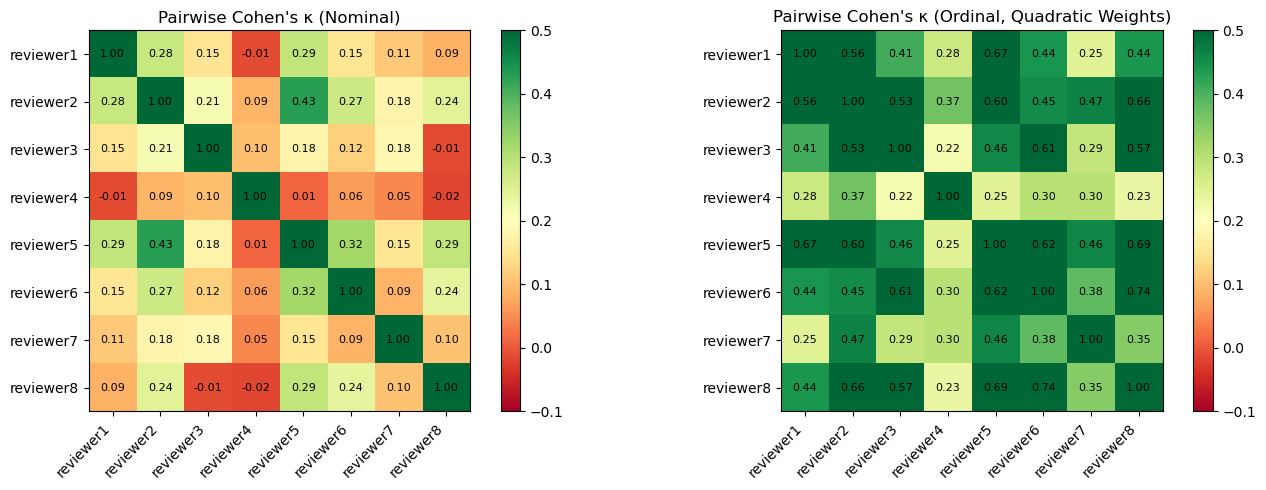

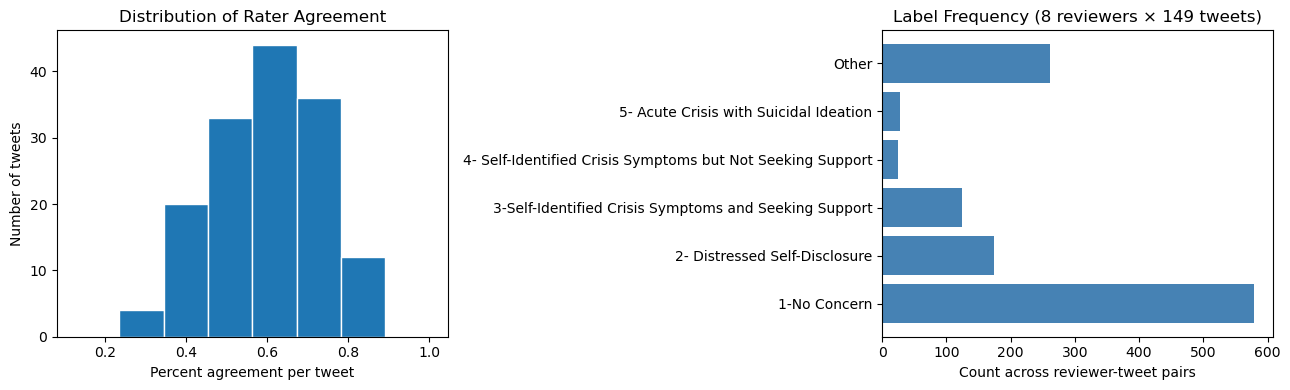

,tweet,agreement,reviewer1,reviewer2,reviewer3,reviewer4,reviewer5,reviewer6,reviewer7,reviewer8
7,I’m done #bipolar #bipolarclub113.1,0.250,Other,2- Distressed Self-Disclosure,2- Distressed Self-Disclosure,1-No Concern,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation,4- Self-Identified Crisis Symptoms but Not See...,3-Self-Identified Crisis Symptoms and Seeking ...
5,I’m done #bipolar #bipolarclub113,0.250,Other,2- Distressed Self-Disclosure,2- Distressed Self-Disclosure,Other,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation,4- Self-Identified Crisis Symptoms but Not See...,3-Self-Identified Crisis Symptoms and Seeking ...
28,Fuckin ideation won’t go away HELP @BipolarClu...,0.250,3-Self-Identified Crisis Symptoms and Seeking ...,3-Self-Identified Crisis Symptoms and Seeking ...,5- Acute Crisis with Suicidal Ideation,1-No Concern,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,1-No Concern,5- Acute Crisis with Suicidal Ideation
21,My current mood is.....probably not safe enoug...,0.250,Other,3-Self-Identified Crisis Symptoms and Seeking ...,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,2- Distressed Self-Disclosure,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation,3-Self-Identified Crisis Symptoms and Seeking ...
9,Dark too dark falling falling fading.....gone,0.375,Other,Other,2- Distressed Self-Disclosure,1-No Concern,5- Acute Crisis with Suicidal Ideation,3-Self-Identified Crisis Symptoms and Seeking ...,5- Acute Crisis with Suicidal Ideation,5- Acute Crisis with Suicidal Ideation
10,"Found this from a “friend “ I know on fb,shit ...",0.375,1-No Concern,2- Distressed Self-Disclosure,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,2- Distressed Self-Disclosure,4- Self-Identified Crisis Symptoms but Not See...,1-No Concern,Other
3,Round&round electricity goes where it stop PLE...,0.375,2- Distressed Self-Disclosure,1-No Concern,1-No Concern,4- Self-Identified Crisis Symptoms but Not See...,2- Distressed Self-Disclosure,1-No Concern,2- Distressed Self-Disclosure,Other
4,Dear winter weather GET THE FUCK OUT OF TEXAS ...,0.375,1-No Concern,2- Distressed Self-Disclosure,Other,1-No Concern,Other,2- Distressed Self-Disclosure,3-Self-Identified Crisis Symptoms and Seeking ...,2- Distressed Self-Disclosure
19,I’m only saying this once FUCK MARILYN MANSON!11,0.375,2- Distressed Self-Disclosure,1-No Concern,1-No Concern,1-No Concern,Other,Other,2- Distressed Self-Disclosure,Other
18,Hi everyone #PTSDChat113,0.375,1-No Concern,1-No Concern,3-Self-Identified Crisis Symptoms and Seeking ...,4- Self-Identified Crisis Symptoms but Not See...,1-No Concern,3-Self-Identified Crisis Symptoms and Seeking ...,2- Distressed Self-Disclosure,3-Self-Identified Crisis Symptoms and Seeking ...


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from itertools import combinations

import krippendorff
from sklearn.metrics import cohen_kappa_score


# ============================================================
# 1. READ MERGED DATA
# ============================================================

df = pd.read_csv("Veteran_Tweet_Label_PTSD_Other_Not_Relevant_merged.csv")


# ============================================================
# 2. KEEP REVIEWER COLUMNS
# ============================================================

REVIEWER_COLS = [
    c for c in df.columns
    if c.startswith("reviewer")
]

ratings = df[REVIEWER_COLS].copy()


# ============================================================
# CHECK LABELS
# ============================================================

print("Labels in merged dataset:")
print(
    ratings
    .stack()
    .value_counts()
)


# ============================================================
# 3. FLEISS' KAPPA
# ============================================================

def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    """Fleiss' kappa for a subjects × raters nominal matrix."""

    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {
        label: i
        for i, label in enumerate(labels)
    }

    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]

    counts = np.zeros(
        (n_subjects, len(labels))
    )

    for i, row in enumerate(rating_matrix.values):

        for label in row:
            counts[
                i,
                label_to_idx[label]
            ] += 1

    n = n_raters

    p_i = (
        (counts * (counts - 1)).sum(axis=1)
        / (n * (n - 1))
    )

    p_bar = p_i.mean()

    p_j = (
        counts.sum(axis=0)
        / (n_subjects * n)
    )

    p_e = (p_j ** 2).sum()

    return (
        (p_bar - p_e)
        / (1 - p_e)
    )


# ============================================================
# 4. PERCENT AGREEMENT
# ============================================================

def percent_agreement(row: pd.Series) -> float:

    counts = Counter(row.values)

    return (
        counts.most_common(1)[0][1]
        / len(row)
    )


tweet_agreement = ratings.apply(
    percent_agreement,
    axis=1
)


# ============================================================
# 5. KRIPPENDORFF'S ALPHA
# ============================================================

LABELS = sorted(
    ratings.stack().unique()
)


# Only the five ordered categories are included
# in the ordinal analysis.
#
# "Other" is intentionally NOT included because
# it is not an ordinal category.

ORDINAL_MAP = {

    "1-No Concern": 1,

    "2- Distressed Self-Disclosure": 2,

    "3-Self-Identified Crisis Symptoms and Seeking Support": 3,

    "4- Self-Identified Crisis Symptoms but Not Seeking Support": 4,

    "5- Acute Crisis with Suicidal Ideation": 5
}


def krippendorff_alpha(
    rating_matrix: pd.DataFrame,
    level: str
) -> float:

    if level == "nominal":

        encoded = (
            rating_matrix.T
            .replace(
                {
                    label: i
                    for i, label
                    in enumerate(LABELS)
                }
            )
            .to_numpy(dtype=float)
        )

    else:

        encoded = (
            rating_matrix
            .apply(
                lambda col:
                col.map(ORDINAL_MAP)
            )
            .T
            .to_numpy(dtype=float)
        )

    return krippendorff.alpha(
        reliability_data=encoded,
        level_of_measurement=level
    )


# ============================================================
# 6. OVERALL IRR SUMMARY
# ============================================================

irr_summary = pd.Series(
    {

        "Number of tweets":
            len(ratings),

        "Number of reviewers":
            len(REVIEWER_COLS),

        "Mean percent agreement":
            tweet_agreement.mean(),

        "Tweets with full agreement (8/8)":
            (tweet_agreement == 1.0).sum(),

        "Tweets with majority agreement (≥5/8)":
            (tweet_agreement >= 5 / 8).sum(),

        "Fleiss' kappa (nominal)":
            fleiss_kappa(ratings),

        "Krippendorff's alpha (nominal)":
            krippendorff_alpha(
                ratings,
                "nominal"
            ),

        "Krippendorff's alpha (ordinal)":
            krippendorff_alpha(
                ratings,
                "ordinal"
            ),
    }
)


print(
    "\n=========================================="
)

print(
    "INTER-RATER RELIABILITY"
)

print(
    "=========================================="
)

print(
    irr_summary
    .to_frame("Value")
    .round(4)
)


# ============================================================
# 7. PAIRWISE COHEN'S KAPPA
# ============================================================

pairwise_nominal = pd.DataFrame(
    index=REVIEWER_COLS,
    columns=REVIEWER_COLS,
    dtype=float
)

pairwise_weighted = pd.DataFrame(
    index=REVIEWER_COLS,
    columns=REVIEWER_COLS,
    dtype=float
)


ordinal_ratings = ratings.apply(
    lambda col:
    col.map(ORDINAL_MAP)
)

ORDINAL_LABELS = sorted(
    ORDINAL_MAP.values()
)


for a, b in combinations(
    REVIEWER_COLS,
    2
):

    # --------------------------------------------------------
    # Nominal Cohen's Kappa
    # --------------------------------------------------------

    mask = (
        ratings[a].notna()
        &
        ratings[b].notna()
    )

    n_valid = mask.sum()

    if n_valid > 0:

        pairwise_nominal.loc[a, b] = (
            cohen_kappa_score(
                ratings.loc[mask, a],
                ratings.loc[mask, b]
            )
        )

        pairwise_nominal.loc[b, a] = (
            pairwise_nominal.loc[a, b]
        )

    else:

        pairwise_nominal.loc[a, b] = np.nan
        pairwise_nominal.loc[b, a] = np.nan


    # --------------------------------------------------------
    # Weighted Cohen's Kappa
    # --------------------------------------------------------

    ordinal_mask = (
        ordinal_ratings[a].notna()
        &
        ordinal_ratings[b].notna()
    )

    n_ordinal = ordinal_mask.sum()

    if n_ordinal > 0:

        pairwise_weighted.loc[a, b] = (
            cohen_kappa_score(
                ordinal_ratings.loc[
                    ordinal_mask,
                    a
                ].astype(int),

                ordinal_ratings.loc[
                    ordinal_mask,
                    b
                ].astype(int),

                labels=ORDINAL_LABELS,

                weights="quadratic"
            )
        )

        pairwise_weighted.loc[b, a] = (
            pairwise_weighted.loc[a, b]
        )

    else:

        pairwise_weighted.loc[a, b] = np.nan
        pairwise_weighted.loc[b, a] = np.nan


# ============================================================
# 8. DIAGONAL
# ============================================================

for col in REVIEWER_COLS:

    pairwise_nominal.loc[
        col,
        col
    ] = 1.0

    pairwise_weighted.loc[
        col,
        col
    ] = 1.0


# ============================================================
# 9. PAIRWISE COHEN'S KAPPA SUMMARY
# ============================================================

off_diagonal = ~np.eye(
    len(REVIEWER_COLS),
    dtype=bool
)


nominal_values = (
    pairwise_nominal
    .where(off_diagonal)
    .stack()
)


weighted_values = (
    pairwise_weighted
    .where(off_diagonal)
    .stack()
)


print(
    "\n=========================================="
)

print(
    "PAIRWISE COHEN'S KAPPA"
)

print(
    "=========================================="
)


print(
    f"Nominal Cohen's κ — "
    f"mean: {nominal_values.mean():.3f}, "
    f"min: {nominal_values.min():.3f}, "
    f"max: {nominal_values.max():.3f}"
)


print(
    f"Weighted Cohen's κ — "
    f"mean: {weighted_values.mean():.3f}, "
    f"min: {weighted_values.min():.3f}, "
    f"max: {weighted_values.max():.3f}"
)


# ============================================================
# 10. VISUALIZE PAIRWISE COHEN'S KAPPA
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


for ax, matrix, title in zip(
    axes,

    [
        pairwise_nominal,
        pairwise_weighted
    ],

    [
        "Pairwise Cohen's κ (Nominal)",
        "Pairwise Cohen's κ "
        "(Ordinal, Quadratic Weights)"
    ]
):

    im = ax.imshow(
        matrix.astype(float),
        vmin=-0.1,
        vmax=0.5,
        cmap="RdYlGn"
    )

    ax.set_xticks(
        range(len(matrix.columns)),
        matrix.columns,
        rotation=45,
        ha="right"
    )

    ax.set_yticks(
        range(len(matrix.index)),
        matrix.index
    )

    ax.set_title(title)

    for i in range(
        len(matrix.index)
    ):

        for j in range(
            len(matrix.columns)
        ):

            val = matrix.iloc[i, j]

            ax.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046
    )


plt.tight_layout()
plt.show()


# ============================================================
# 11. AGREEMENT DISTRIBUTION + LABEL FREQUENCY
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4)
)


# Agreement distribution

axes[0].hist(
    tweet_agreement,
    bins=8,
    range=(0.125, 1.001),
    edgecolor="white"
)

axes[0].set_xlabel(
    "Percent agreement per tweet"
)

axes[0].set_ylabel(
    "Number of tweets"
)

axes[0].set_title(
    "Distribution of Rater Agreement"
)


# Label frequency

label_counts = (
    ratings
    .stack()
    .value_counts()
    .sort_index()
)

axes[1].barh(
    label_counts.index,
    label_counts.values,
    color="steelblue"
)

axes[1].set_xlabel(
    "Count across reviewer-tweet pairs"
)

axes[1].set_title(
    f"Label Frequency "
    f"({len(REVIEWER_COLS)} reviewers × "
    f"{len(ratings)} tweets)"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. LOWEST AGREEMENT TWEETS
# ============================================================

filtered_tweets = df.copy()

filtered_tweets["agreement"] = (
    tweet_agreement
)

low_agreement = (
    filtered_tweets
    .sort_values("agreement")
    .loc[
        :,
        [
            "tweet",
            "agreement",
            *REVIEWER_COLS
        ]
    ]
    .head(10)
)


low_agreement